# Resultados finales — comparativa de 5 modelos en BDD100K

Genera todas las gráficas del capítulo de resultados a partir de `resumen.json`
(salida de `consolidar.py --json resumen.json`). Cada figura se guarda en
`figuras_resultados/` en PNG (300 dpi, para revisar) y PDF (vectorial, para
`\includegraphics` en la memoria).

**Aviso de FPS**: las cifras de velocidad de `resumen.json` solo son válidas si
los 18 runs se evaluaron en una única sesión seguida con la máquina en reposo
(ver `docs/REGISTRO_ENTRENAMIENTOS.md`, "Sesión de consolidación de FPS"). Si no
fue así, trata las gráficas que usan FPS como orientativas, no definitivas.

Paleta y método siguiendo la skill `dataviz` del repositorio: color categórico en
orden fijo por modelo, color secuencial de un solo tono para magnitudes, y
diverging azul/rojo para diferencias con signo. En los scatter/bubble (6
entidades, por encima del límite de 3 series que garantiza distinción de color
en todos los pares) cada punto lleva además etiqueta directa y forma de marcador
distinta, así la identidad no depende solo del color.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

RESUMEN_PATH = Path("../resumen.json")
FIG_DIR = Path("figuras_resultados")
FIG_DIR.mkdir(exist_ok=True)

with RESUMEN_PATH.open(encoding="utf-8") as f:
    data = json.load(f)

# Orden fijo de los modelos: fija tambien el color de cada uno en todas las
# graficas (la identidad de color sigue a la entidad, nunca a su rango).
MODELOS = ["YOLO11m (A)", "YOLO11m (B)", "Faster R-CNN", "SSD300", "DETR", "CNN baseline"]
MODELOS = [m for m in MODELOS if m in data]

CLASS_NAMES = ["person", "rider", "car", "truck", "bus",
               "train", "motor", "bike", "traffic light", "traffic sign"]

# Paleta validada (dataviz skill, references/palette.md), modo claro.
MODEL_COLORS = {
    "YOLO11m (A)":  "#2a78d6",  # slot 1 azul
    "YOLO11m (B)":  "#eb6834",  # slot 2 naranja
    "Faster R-CNN": "#1baf7a",  # slot 3 aqua
    "SSD300":       "#eda100",  # slot 4 amarillo
    "DETR":         "#e87ba4",  # slot 5 magenta
    "CNN baseline": "#008300",  # slot 6 verde
}
MODEL_MARKERS = {
    "YOLO11m (A)": "o", "YOLO11m (B)": "s", "Faster R-CNN": "^",
    "SSD300": "D", "DETR": "v", "CNN baseline": "P",
}
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
BASELINE_COLOR = "#c3c2b7"
SURFACE = "#fcfcfb"
STATUS_GOOD = "#0ca30c"
STATUS_CRITICAL = "#d03b3b"
DIVERGING_POS = "#2a78d6"
DIVERGING_NEG = "#e34948"

SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#1c5cab", "#0d366b"]
CMAP_BLUE = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE_COLOR,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK_PRIMARY,
    "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRID_COLOR,
    "grid.linewidth": 0.8,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "font.size": 10.5,
    "figure.dpi": 110,
})


def media(modelo, clave):
    v = data[modelo].get(clave)
    return v["media"] if v else None


def desv(modelo, clave):
    v = data[modelo].get(clave)
    return (v["desv"] or 0) if v else 0


def ap_clase(modelo, clase):
    v = data[modelo]["per_class"].get(clase)
    return (v["media"] if v else None), ((v["desv"] or 0) if v else 0)


def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{nombre}.pdf", bbox_inches="tight")
    print(f"Guardada: {FIG_DIR / nombre}.png (+ .pdf)")


def etiquetas_barras(ax, rects, fmt="{:.1f}", offset=1.0, size=8.5, color=INK_SECONDARY):
    for r in rects:
        h = r.get_height()
        if h is None or np.isnan(h):
            continue
        ax.annotate(fmt.format(h), xy=(r.get_x() + r.get_width() / 2, h),
                    xytext=(0, offset), textcoords="offset points",
                    ha="center", va="bottom", fontsize=size, color=color)


def limpiar_ejes(ax):
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE_COLOR)
    ax.tick_params(length=0)


print(f"Modelos cargados: {MODELOS}")

Modelos cargados: ['YOLO11m (A)', 'YOLO11m (B)', 'Faster R-CNN', 'SSD300', 'DETR', 'CNN baseline']


## Tabla resumen (media ± desviación típica, 3 semillas)

In [2]:
filas = []
for m in MODELOS:
    filas.append({
        "Modelo": m,
        "mAP@50": f"{media(m,'map50'):.2f} ± {desv(m,'map50'):.2f}",
        "mAP@50-95": f"{media(m,'map50_95'):.2f} ± {desv(m,'map50_95'):.2f}",
        "Precision": f"{media(m,'precision'):.2f} ± {desv(m,'precision'):.2f}",
        "Recall": f"{media(m,'recall'):.2f} ± {desv(m,'recall'):.2f}",
        "F1": f"{media(m,'f1'):.2f} ± {desv(m,'f1'):.2f}",
        "FPS": f"{media(m,'fps'):.1f} ± {desv(m,'fps'):.1f}",
        "GFLOPs": data[m].get("gflops"),
        "Params (M)": data[m].get("params_m"),
    })
df_resumen = pd.DataFrame(filas).set_index("Modelo")
df_resumen

,mAP@50,mAP@50-95,Precision,Recall,F1,FPS,GFLOPs,Params (M)
Modelo,,,,,,,,
YOLO11m (A),47.71 ± 0.25,25.72 ± 0.22,68.60 ± 1.45,46.92 ± 0.61,51.56 ± 0.49,110.2 ± 3.1,40.9,20.06
YOLO11m (B),36.50 ± 0.23,19.08 ± 0.11,57.98 ± 2.24,39.30 ± 2.35,43.52 ± 2.59,111.7 ± 4.0,40.9,20.06
Faster R-CNN,50.99 ± 0.27,26.28 ± 0.17,67.77 ± 1.85,48.67 ± 1.22,51.75 ± 0.59,22.7 ± 0.1,748.1,43.30
SSD300,20.80 ± 0.05,10.29 ± 0.11,51.95 ± 0.97,22.51 ± 0.35,27.46 ± 0.05,89.8 ± 0.5,61.8,24.95
DETR,22.77 ± 0.38,9.58 ± 0.31,37.53 ± 3.16,33.77 ± 2.03,30.76 ± 0.81,27.0 ± 0.1,185.1,41.50
CNN baseline,27.07 ± 0.51,10.85 ± 0.17,45.11 ± 4.53,31.85 ± 2.72,33.80 ± 1.88,65.8 ± 0.3,93.4,1.89


## Figura 1 — mAP@50 y mAP@50-95 por modelo

Comparativa principal, ordenada de mayor a menor mAP@50-95. Barras de error =
desviación típica sobre las 3 semillas.

Guardada: figuras_resultados\01_map_por_modelo.png (+ .pdf)


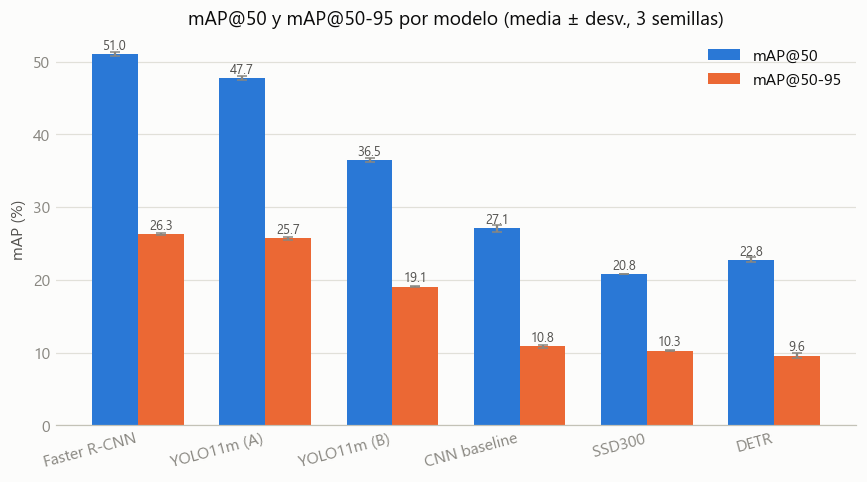

In [3]:
orden = sorted(MODELOS, key=lambda m: media(m, "map50_95"), reverse=True)
x = np.arange(len(orden))
w = 0.36

fig, ax = plt.subplots(figsize=(8, 4.5))
r1 = ax.bar(x - w/2, [media(m, "map50") for m in orden], w,
            yerr=[desv(m, "map50") for m in orden], capsize=3,
            color="#2a78d6", label="mAP@50", ecolor=INK_MUTED)
r2 = ax.bar(x + w/2, [media(m, "map50_95") for m in orden], w,
            yerr=[desv(m, "map50_95") for m in orden], capsize=3,
            color="#eb6834", label="mAP@50-95", ecolor=INK_MUTED)
etiquetas_barras(ax, r1)
etiquetas_barras(ax, r2)

ax.set_xticks(x)
ax.set_xticklabels(orden, rotation=15, ha="right")
ax.set_ylabel("mAP (%)")
ax.set_title("mAP@50 y mAP@50-95 por modelo (media ± desv., 3 semillas)")
ax.legend(frameon=False, loc="upper right")
limpiar_ejes(ax)
fig.tight_layout()
guardar(fig, "01_map_por_modelo")
plt.show()

## Figura 2 — Precision, Recall y F1 (en el punto de máximo F1)

Guardada: figuras_resultados\02_precision_recall_f1.png (+ .pdf)


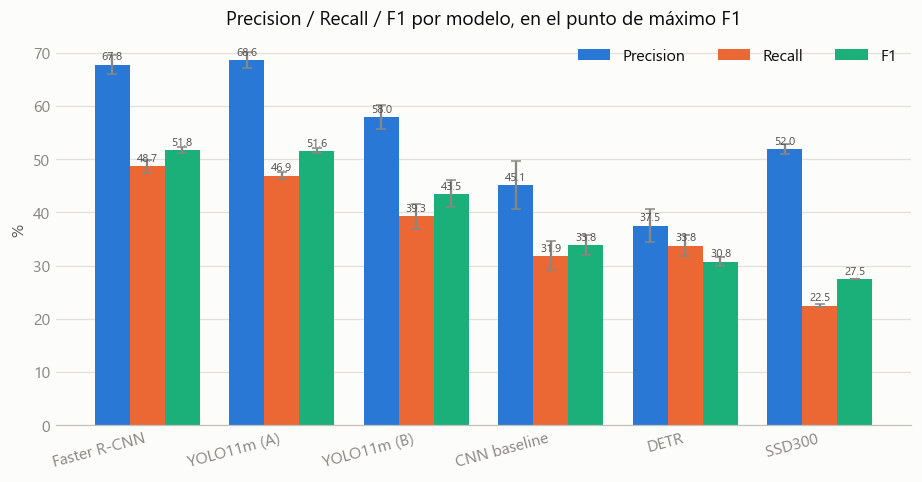

In [4]:
orden = sorted(MODELOS, key=lambda m: media(m, "f1"), reverse=True)
x = np.arange(len(orden))
w = 0.26
metricas = [("precision", "Precision", "#2a78d6"),
            ("recall", "Recall", "#eb6834"),
            ("f1", "F1", "#1baf7a")]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for i, (clave, etq, color) in enumerate(metricas):
    off = (i - 1) * w
    r = ax.bar(x + off, [media(m, clave) for m in orden], w,
               yerr=[desv(m, clave) for m in orden], capsize=3,
               color=color, label=etq, ecolor=INK_MUTED)
    etiquetas_barras(ax, r, size=7.5)

ax.set_xticks(x)
ax.set_xticklabels(orden, rotation=15, ha="right")
ax.set_ylabel("%")
ax.set_title("Precision / Recall / F1 por modelo, en el punto de máximo F1")
ax.legend(frameon=False, loc="upper right", ncol=3)
limpiar_ejes(ax)
fig.tight_layout()
guardar(fig, "02_precision_recall_f1")
plt.show()

## Figura 3 — AP por tamaño de objeto (small / medium / large)

Es la lectura clave del estudio: el 75.7 % de los objetos mide menos de 32 px
nativos, así que el AP en "small" es el que más pesa en la práctica.

Guardada: figuras_resultados\03_ap_por_tamano.png (+ .pdf)


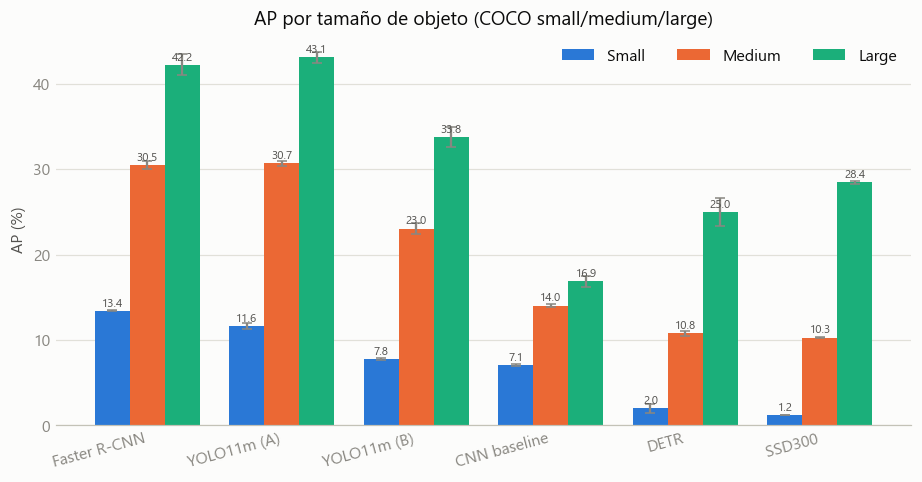

In [5]:
orden = sorted(MODELOS, key=lambda m: media(m, "map_small"), reverse=True)
x = np.arange(len(orden))
w = 0.26
tamanos = [("map_small", "Small", "#2a78d6"),
           ("map_medium", "Medium", "#eb6834"),
           ("map_large", "Large", "#1baf7a")]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for i, (clave, etq, color) in enumerate(tamanos):
    off = (i - 1) * w
    r = ax.bar(x + off, [media(m, clave) for m in orden], w,
               yerr=[desv(m, clave) for m in orden], capsize=3,
               color=color, label=etq, ecolor=INK_MUTED)
    etiquetas_barras(ax, r, size=7.5)

ax.set_xticks(x)
ax.set_xticklabels(orden, rotation=15, ha="right")
ax.set_ylabel("AP (%)")
ax.set_title("AP por tamaño de objeto (COCO small/medium/large)")
ax.legend(frameon=False, loc="upper right", ncol=3)
limpiar_ejes(ax)
fig.tight_layout()
guardar(fig, "03_ap_por_tamano")
plt.show()

## Figura 4 — Mapa de calor: AP@50-95 por clase × modelo

Codificación secuencial de un solo tono (magnitud), de claro a oscuro.

Guardada: figuras_resultados\04_heatmap_ap_por_clase.png (+ .pdf)


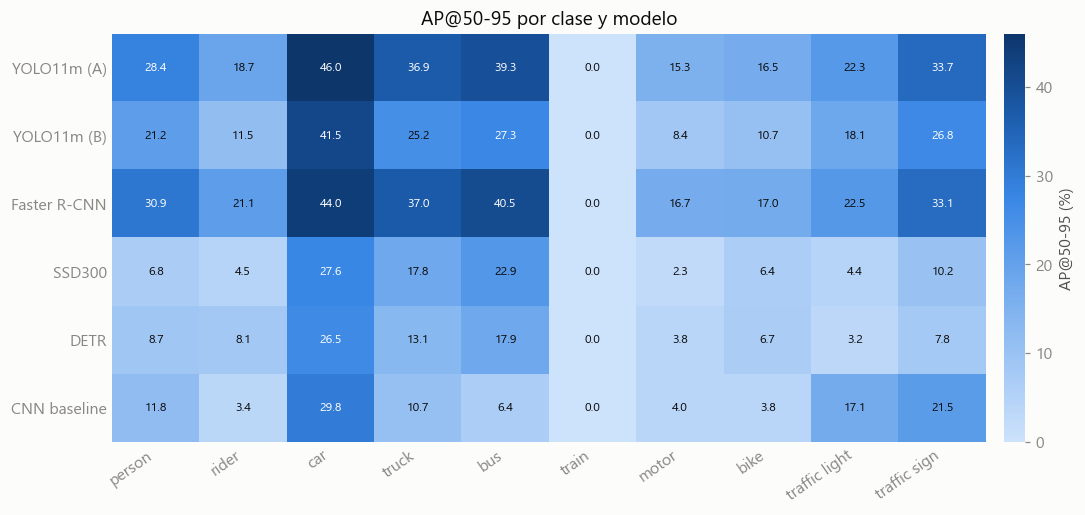

In [6]:
matriz = np.array([[ap_clase(m, c)[0] if ap_clase(m, c)[0] is not None else np.nan
                     for c in CLASS_NAMES] for m in MODELOS])

fig, ax = plt.subplots(figsize=(10, 0.55 * len(MODELOS) + 1.5))
im = ax.imshow(matriz, cmap=CMAP_BLUE, aspect="auto", vmin=0, vmax=np.nanmax(matriz))

ax.set_xticks(range(len(CLASS_NAMES)))
ax.set_xticklabels(CLASS_NAMES, rotation=35, ha="right")
ax.set_yticks(range(len(MODELOS)))
ax.set_yticklabels(MODELOS)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
ax.grid(False)

# Umbral de luminosidad para decidir el color del texto (ink claro sobre celda oscura)
umbral = np.nanmax(matriz) * 0.55
for i in range(len(MODELOS)):
    for j in range(len(CLASS_NAMES)):
        v = matriz[i, j]
        if np.isnan(v):
            continue
        color_txt = "#ffffff" if v > umbral else INK_PRIMARY
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color=color_txt)

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("AP@50-95 (%)", color=INK_SECONDARY)
cbar.outline.set_visible(False)

ax.set_title("AP@50-95 por clase y modelo")
fig.tight_layout()
guardar(fig, "04_heatmap_ap_por_clase")
plt.show()

## Figura 5 — AP por clase, barras agrupadas (orden por número de instancias)

Mismos datos que la Figura 4 en forma de barras, más fácil de leer cifra a
cifra. Las clases se ordenan de mayor a menor número de instancias de GT en
validación (`car` domina el desbalanceo, `train` es anécdota con 2 instancias).

Guardada: figuras_resultados\05_ap_por_clase_barras.png (+ .pdf)


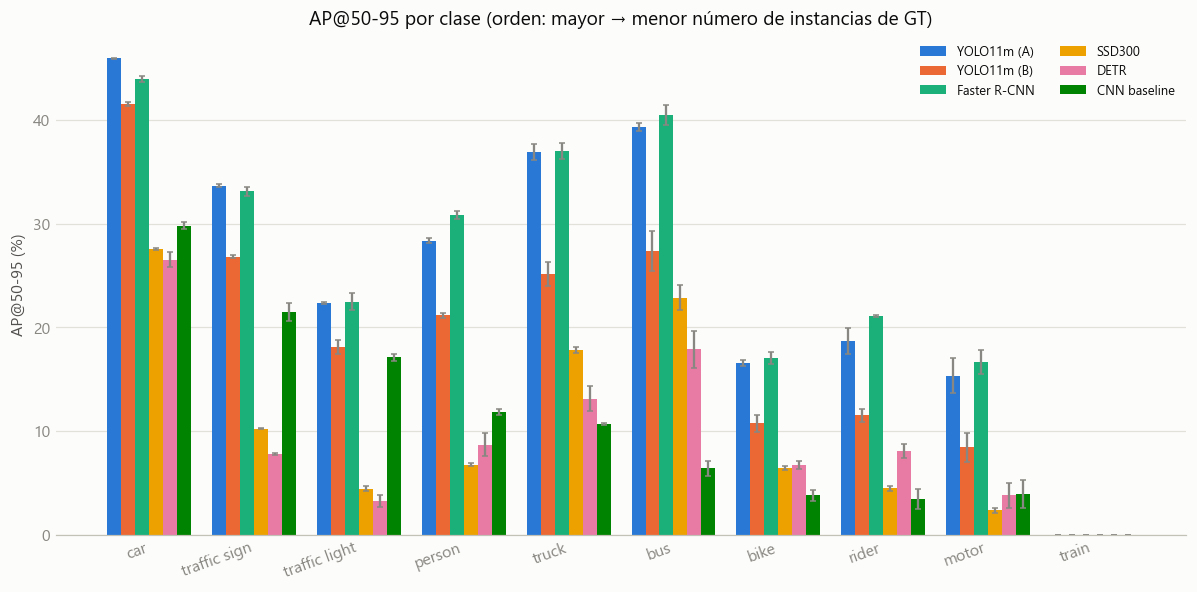

In [7]:
orden_clases_por_instancias = ["car", "traffic sign", "traffic light", "person",
                                "truck", "bus", "bike", "rider", "motor", "train"]

fig, ax = plt.subplots(figsize=(11, 5.5))
n = len(MODELOS)
w = 0.8 / n
x = np.arange(len(orden_clases_por_instancias))

for i, m in enumerate(MODELOS):
    vals = [ap_clase(m, c)[0] for c in orden_clases_por_instancias]
    errs = [ap_clase(m, c)[1] for c in orden_clases_por_instancias]
    off = (i - (n - 1) / 2) * w
    ax.bar(x + off, vals, w, yerr=errs, capsize=2,
           color=MODEL_COLORS[m], label=m, ecolor=INK_MUTED, linewidth=0)

ax.set_xticks(x)
ax.set_xticklabels(orden_clases_por_instancias, rotation=20, ha="right")
ax.set_ylabel("AP@50-95 (%)")
ax.set_title("AP@50-95 por clase (orden: mayor → menor número de instancias de GT)")
ax.legend(frameon=False, loc="upper right", ncol=2, fontsize=8.5)
limpiar_ejes(ax)
fig.tight_layout()
guardar(fig, "05_ap_por_clase_barras")
plt.show()

## Figura 6 — mAP@50-95 vs FPS (frontera de eficiencia)

Eje X logarítmico: el rango de FPS va de ~12 (Faster R-CNN) a ~92 (YOLO11m).
Con 6 modelos por encima del límite de 3 series que garantiza color distinguible
en *todos* los pares, cada punto lleva además etiqueta directa y forma de
marcador propia — la identidad no depende solo del color.

Guardada: figuras_resultados\06_scatter_map_vs_fps.png (+ .pdf)


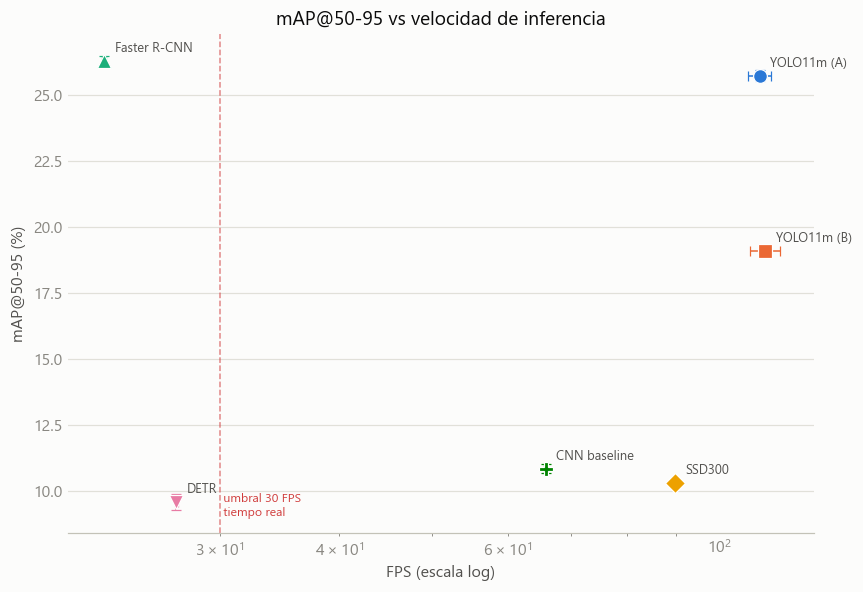

In [8]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for m in MODELOS:
    fps_m, fps_d = media(m, "fps"), desv(m, "fps")
    map_m, map_d = media(m, "map50_95"), desv(m, "map50_95")
    ax.errorbar(fps_m, map_m, xerr=fps_d, yerr=map_d, fmt=MODEL_MARKERS[m],
                color=MODEL_COLORS[m], ecolor=MODEL_COLORS[m], elinewidth=1,
                capsize=3, markersize=9, markeredgecolor="white",
                markeredgewidth=0.8, label=m)
    ax.annotate(m, (fps_m, map_m), xytext=(7, 6), textcoords="offset points",
                fontsize=8.5, color=INK_SECONDARY)

ax.axvline(30, color=STATUS_CRITICAL, linestyle="--", linewidth=1, alpha=0.6)
ax.text(30, ax.get_ylim()[1]*0.02 + ax.get_ylim()[0], " umbral 30 FPS\n tiempo real",
        color=STATUS_CRITICAL, fontsize=8, va="bottom")

ax.set_xscale("log")
ax.set_xlabel("FPS (escala log)")
ax.set_ylabel("mAP@50-95 (%)")
ax.set_title("mAP@50-95 vs velocidad de inferencia")
limpiar_ejes(ax)
fig.tight_layout()
guardar(fig, "06_scatter_map_vs_fps")
plt.show()

## Figura 7 — mAP@50-95 vs coste computacional (GFLOPs)

Misma lógica que la Figura 6, pero frente al coste teórico en lugar de la
velocidad medida — separa "arquitectura barata" de "máquina rápida en esta GPU
concreta".

Guardada: figuras_resultados\07_scatter_map_vs_gflops.png (+ .pdf)


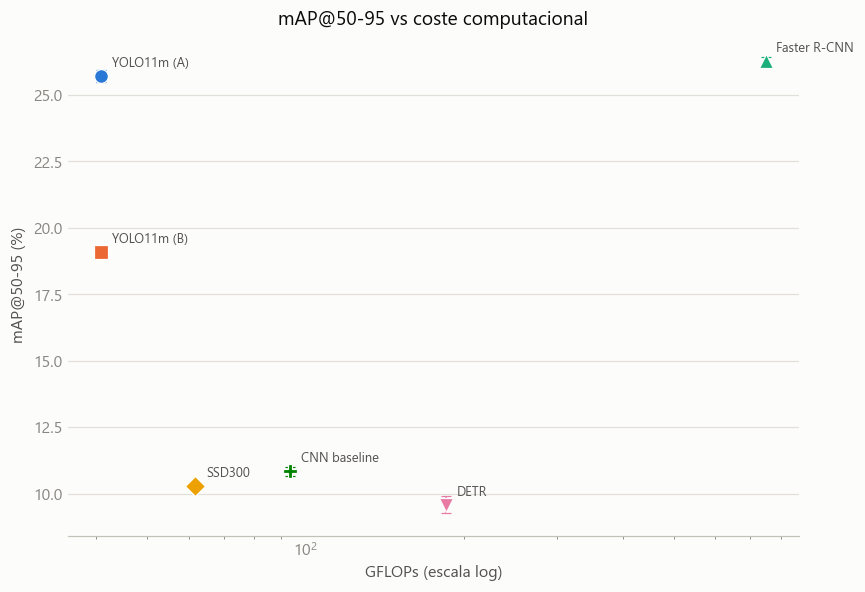

In [9]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for m in MODELOS:
    g = data[m].get("gflops")
    map_m, map_d = media(m, "map50_95"), desv(m, "map50_95")
    ax.errorbar(g, map_m, yerr=map_d, fmt=MODEL_MARKERS[m],
                color=MODEL_COLORS[m], ecolor=MODEL_COLORS[m], elinewidth=1,
                capsize=3, markersize=9, markeredgecolor="white",
                markeredgewidth=0.8, label=m)
    ax.annotate(m, (g, map_m), xytext=(7, 6), textcoords="offset points",
                fontsize=8.5, color=INK_SECONDARY)

ax.set_xscale("log")
ax.set_xlabel("GFLOPs (escala log)")
ax.set_ylabel("mAP@50-95 (%)")
ax.set_title("mAP@50-95 vs coste computacional")
limpiar_ejes(ax)
fig.tight_layout()
guardar(fig, "07_scatter_map_vs_gflops")
plt.show()

## Figura 8 — Burbujas: FPS vs mAP@50-95, tamaño = parámetros (M)

Combina las tres señales de eficiencia en una sola figura.

Guardada: figuras_resultados\08_bubble_fps_map_params.png (+ .pdf)


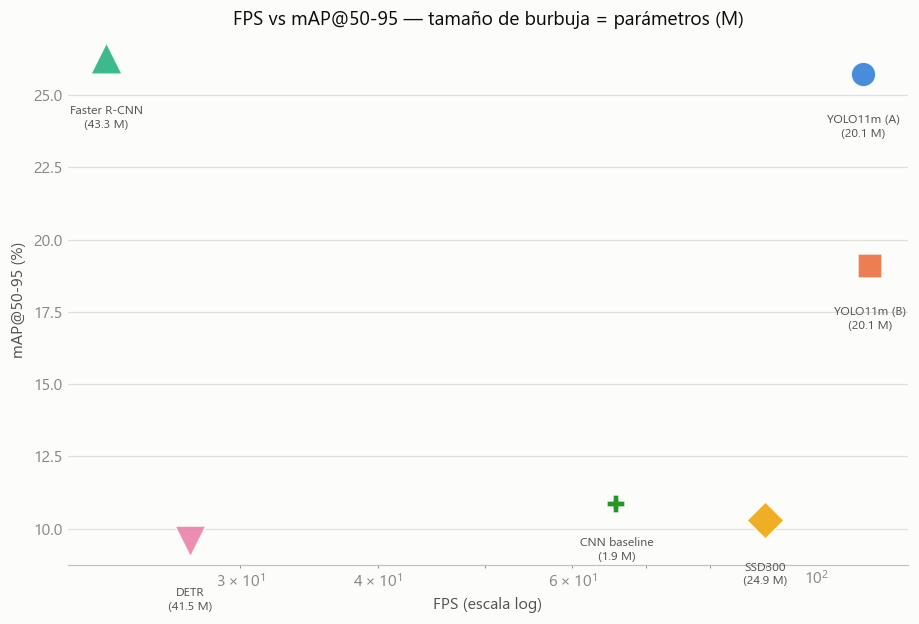

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 5.8))
params = np.array([data[m]["params_m"] for m in MODELOS])
# Escala de area, no de radio (percepcion correcta de magnitud en burbujas).
tam = 300 * (params / params.max()) + 120

for m, s in zip(MODELOS, tam):
    fps_m = media(m, "fps")
    map_m = media(m, "map50_95")
    ax.scatter(fps_m, map_m, s=s, color=MODEL_COLORS[m], alpha=0.85,
               edgecolor="white", linewidth=1, marker=MODEL_MARKERS[m], label=m, zorder=3)
    ax.annotate(f"{m}\n({data[m]['params_m']:.1f} M)", (fps_m, map_m),
                xytext=(0, -np.sqrt(s) - 10), textcoords="offset points",
                fontsize=8, color=INK_SECONDARY, ha="center", va="top")

ax.set_xscale("log")
ax.set_xlabel("FPS (escala log)")
ax.set_ylabel("mAP@50-95 (%)")
ax.set_title("FPS vs mAP@50-95 — tamaño de burbuja = parámetros (M)")
limpiar_ejes(ax)
fig.tight_layout()
guardar(fig, "08_bubble_fps_map_params")
plt.show()

## Figura 9 — Latencia por imagen y cumplimiento del umbral de tiempo real (30 FPS)

Color de estado (no identidad de modelo): verde = cumple, rojo = no cumple,
siempre acompañado de la etiqueta "Sí"/"No" — el color de estado nunca va solo.

C:\Users\julio\AppData\Local\Temp\ipykernel_29952\1162789376.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(orden, rotation=15, ha="right")


Guardada: figuras_resultados\09_latencia_umbral_realtime.png (+ .pdf)


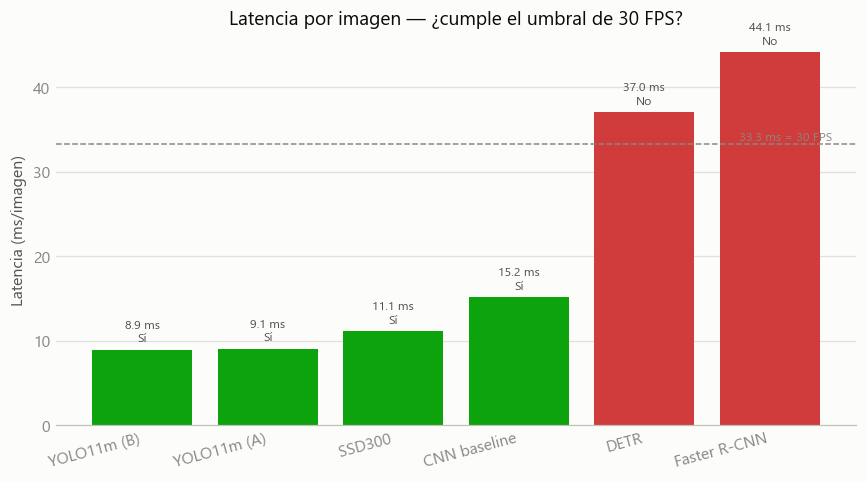

In [11]:
UMBRAL_FPS = 30.0
orden = sorted(MODELOS, key=lambda m: media(m, "fps"), reverse=True)
lat_ms = [1000.0 / media(m, "fps") for m in orden]
cumple = [media(m, "fps") >= UMBRAL_FPS for m in orden]
colores = [STATUS_GOOD if c else STATUS_CRITICAL for c in cumple]

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(orden, lat_ms, color=colores)
ax.axhline(1000 / UMBRAL_FPS, color=INK_MUTED, linestyle="--", linewidth=1)
ax.text(len(orden) - 0.5, 1000 / UMBRAL_FPS, f" {1000/UMBRAL_FPS:.1f} ms = {UMBRAL_FPS:.0f} FPS",
        va="bottom", ha="right", fontsize=8, color=INK_MUTED)

for r, c, ok in zip(barras, lat_ms, cumple):
    ax.annotate(f"{c:.1f} ms\n{'Sí' if ok else 'No'}",
                xy=(r.get_x() + r.get_width()/2, r.get_height()),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=8, color=INK_SECONDARY)

ax.set_ylabel("Latencia (ms/imagen)")
ax.set_title(f"Latencia por imagen — ¿cumple el umbral de {UMBRAL_FPS:.0f} FPS?")
ax.set_xticklabels(orden, rotation=15, ha="right")
limpiar_ejes(ax)
fig.tight_layout()
guardar(fig, "09_latencia_umbral_realtime")
plt.show()

## Figura 10 — Eficiencia: mAP@50-95 por GFLOP

Un solo valor por modelo (mAP@50-95 dividido entre GFLOPs) — qué arquitectura
saca más partido a cada unidad de cómputo.

C:\Users\julio\AppData\Local\Temp\ipykernel_29952\4272902459.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(orden, rotation=15, ha="right")


Guardada: figuras_resultados\10_eficiencia_map_por_gflop.png (+ .pdf)


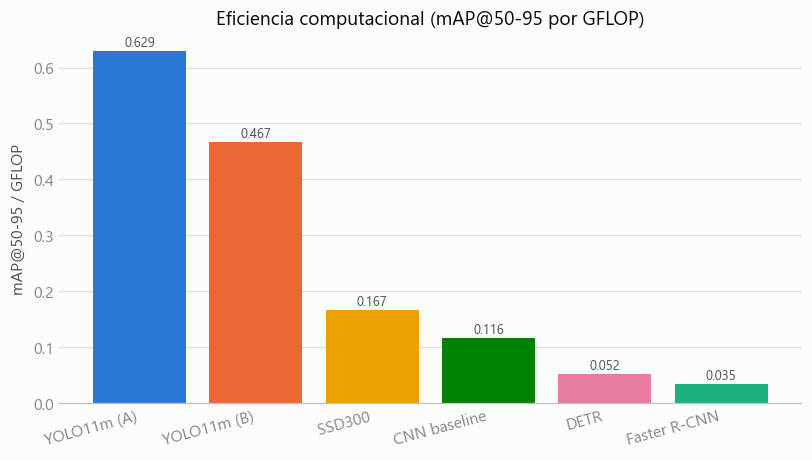

In [12]:
efic = {m: media(m, "map50_95") / data[m]["gflops"] for m in MODELOS}
orden = sorted(MODELOS, key=lambda m: efic[m], reverse=True)

fig, ax = plt.subplots(figsize=(7.5, 4.3))
barras = ax.bar(orden, [efic[m] for m in orden], color=[MODEL_COLORS[m] for m in orden])
etiquetas_barras(ax, barras, fmt="{:.3f}")

ax.set_ylabel("mAP@50-95 / GFLOP")
ax.set_title("Eficiencia computacional (mAP@50-95 por GFLOP)")
ax.set_xticklabels(orden, rotation=15, ha="right")
limpiar_ejes(ax)
fig.tight_layout()
guardar(fig, "10_eficiencia_map_por_gflop")
plt.show()

## Figura 11 — Ablación YOLO11m: augmentación completa (A) vs solo flip (B)

Métricas generales, con el mismo color por variante que en las Figuras 6-8
(azul = A, naranja = B).

Guardada: figuras_resultados\11_ablacion_metricas_generales.png (+ .pdf)


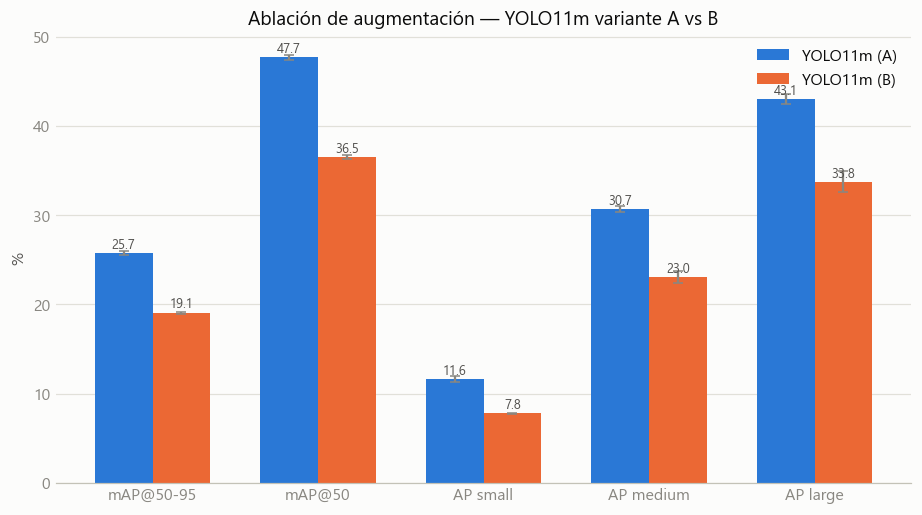

In [13]:
A, B = "YOLO11m (A)", "YOLO11m (B)"
assert A in data and B in data, "Faltan las dos variantes de YOLO11m para la ablación"

metricas = [("map50_95", "mAP@50-95"), ("map50", "mAP@50"),
            ("map_small", "AP small"), ("map_medium", "AP medium"),
            ("map_large", "AP large")]
x = np.arange(len(metricas))
w = 0.35

fig, ax = plt.subplots(figsize=(8.5, 4.8))
rA = ax.bar(x - w/2, [media(A, k) for k, _ in metricas], w,
            yerr=[desv(A, k) for k, _ in metricas], capsize=3,
            color=MODEL_COLORS[A], label=A, ecolor=INK_MUTED)
rB = ax.bar(x + w/2, [media(B, k) for k, _ in metricas], w,
            yerr=[desv(B, k) for k, _ in metricas], capsize=3,
            color=MODEL_COLORS[B], label=B, ecolor=INK_MUTED)
etiquetas_barras(ax, rA)
etiquetas_barras(ax, rB)

ax.set_xticks(x)
ax.set_xticklabels([e for _, e in metricas])
ax.set_ylabel("%")
ax.set_title("Ablación de augmentación — YOLO11m variante A vs B")
ax.legend(frameon=False, loc="upper right")
limpiar_ejes(ax)
fig.tight_layout()
guardar(fig, "11_ablacion_metricas_generales")
plt.show()

## Figura 12 — Ablación: diferencia de AP por clase (A − B)

Barras divergentes: azul = A por encima de B (la augmentación ayuda en esa
clase), rojo = B por encima de A. Ordenado por magnitud de la diferencia.

Guardada: figuras_resultados\12_ablacion_diferencia_por_clase.png (+ .pdf)


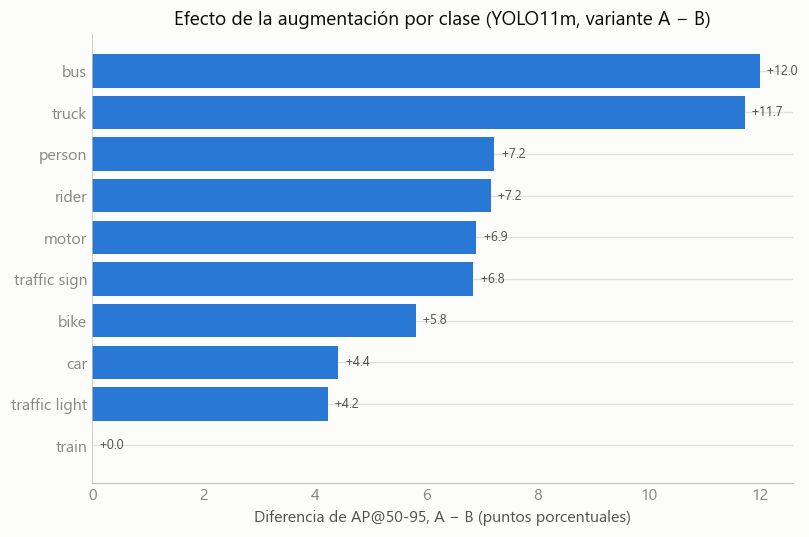

In [14]:
difs = []
for c in CLASS_NAMES:
    va, _ = ap_clase(A, c)
    vb, _ = ap_clase(B, c)
    if va is not None and vb is not None:
        difs.append((c, va - vb))
difs.sort(key=lambda t: t[1])

clases_ord = [c for c, _ in difs]
valores = [v for _, v in difs]
colores = [DIVERGING_POS if v >= 0 else DIVERGING_NEG for v in valores]

fig, ax = plt.subplots(figsize=(7.5, 5))
y = np.arange(len(clases_ord))
ax.barh(y, valores, color=colores)
ax.axvline(0, color=BASELINE_COLOR, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(clases_ord)
ax.set_xlabel("Diferencia de AP@50-95, A − B (puntos porcentuales)")
ax.set_title("Efecto de la augmentación por clase (YOLO11m, variante A − B)")

for yi, v in zip(y, valores):
    ax.annotate(f"{v:+.1f}", xy=(v, yi), xytext=(4 if v >= 0 else -4, 0),
                textcoords="offset points", ha="left" if v >= 0 else "right",
                va="center", fontsize=8.5, color=INK_SECONDARY)

limpiar_ejes(ax)
ax.spines["left"].set_visible(False)
fig.tight_layout()
guardar(fig, "12_ablacion_diferencia_por_clase")
plt.show()

## Resumen de ficheros generados

Todas las figuras quedan en `figuras_resultados/`, en PNG (300 dpi) y PDF
(vectorial, para `\includegraphics` directo en la memoria LaTeX).

In [15]:
for p in sorted(FIG_DIR.glob("*.pdf")):
    print(p.name)

01_map_por_modelo.pdf
02_precision_recall_f1.pdf
03_ap_por_tamano.pdf
04_heatmap_ap_por_clase.pdf
05_ap_por_clase_barras.pdf
06_scatter_map_vs_fps.pdf
07_scatter_map_vs_gflops.pdf
08_bubble_fps_map_params.pdf
09_latencia_umbral_realtime.pdf
10_eficiencia_map_por_gflop.pdf
11_ablacion_metricas_generales.pdf
12_ablacion_diferencia_por_clase.pdf


## Conclusiones para la memoria

- **Faster R-CNN obtiene el mAP@50-95 más alto (26.28±0.17%), pero por un
  margen mínimo sobre YOLO11m(A) (25.72±0.22%)** — 0.56 pp de diferencia,
  estadísticamente significativa (ver `significancia_estadistica/`) pero
  pequeña en términos absolutos.
- **Ponderado por coste, YOLO11m(A) es la mejor relación precisión/eficiencia
  del estudio**: 40.9 GFLOPs frente a los 748.1 de Faster R-CNN (18.3× menos)
  y ~110 FPS frente a ~23 — casi el mismo mAP a una fracción del coste.
- **Los objetos pequeños son el punto débil común a los 5 modelos** (AP small
  entre 1.17% y 13.43%, muy por debajo del AP large de 16.87%-43.07%),
  coherente con que el 75.7% de los objetos de BDD100K miden <32 px nativos —
  no es un fallo de un modelo concreto, es un límite del dataset a esa escala.
- **Solo YOLO11m (A/B), SSD300 y CNN baseline superan el umbral de 30 FPS en
  tiempo real**; Faster R-CNN y DETR se quedan cerca pero no lo alcanzan.
- **La ablación de augmentación es la diferencia más grande de todo el
  estudio en términos relativos**: +6.64 pp de mAP@50-95 (25.72 vs 19.08) solo
  por pasar de "flip únicamente" a augmentación completa — mayor que la
  diferencia entre varias arquitecturas distintas.